# Week 7: Read an agent's log

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. You will need a free Gemini API key from Google AI Studio (aistudio.google.com) and the course Replicate token. You can add them in the Secrets panel on the left as GEMINI_API_KEY and REPLICATE_API_TOKEN. The outputs below are from one run on the museum café brief.

## 1. Setup

This reads your two keys. If they are not in the Secrets panel, it will ask you to paste them.

In [1]:
import base64, io, json, os, sys, time
import requests
from PIL import Image
from IPython.display import HTML, display

IN_COLAB = "google.colab" in sys.modules

def get_key(name):
    """A key from the environment, then from Colab's Secrets panel, then typed in."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        from getpass import getpass
        return getpass(name + ": ")

GEMINI_KEY = get_key("GEMINI_API_KEY")        # free, from aistudio.google.com
REPLICATE_KEY = get_key("REPLICATE_API_TOKEN")  # the course token
MODEL = "gemini-2.5-flash"
print("ready")

ready


## 2. The brief

BRIEF is the design task for the agent, and MAX_ROUNDS is the most images it can make. This cell also downloads the 56 museum chairs from week 4 and puts them on one reference sheet for the agent.

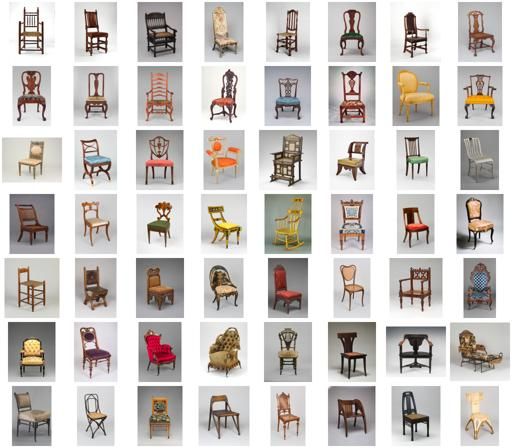

In [2]:
BRIEF = ("Design a new side chair for a museum café. It should draw on the 56 historical chairs in the museum's "
         "collection, shown in the reference sheet, and work in a busy café.")
MAX_ROUNDS = 4

# a reference sheet of the 56 museum chairs from week 4
base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
names = [l.split(",")[0] for l in requests.get(base + "credits.csv", timeout=60).text.splitlines()[1:]]
thumbs = []
for n in names:
    im = Image.open(io.BytesIO(requests.get(base + "train/" + n, timeout=60).content)).convert("RGB")
    im.thumbnail((120, 120))
    thumbs.append(im)
sheet = Image.new("RGB", (8 * 128, 7 * 128), "white")
for i, im in enumerate(thumbs):
    sheet.paste(im, ((i % 8) * 128 + (128 - im.width) // 2, (i // 8) * 128 + (128 - im.height) // 2))
sheet.save("reference-sheet.jpg", quality=85)
sheet.resize((sheet.width // 2, sheet.height // 2))

## 3. The agent

These functions send text and images to Gemini, make an image with FLUX.1 [schnell] on Replicate, and save every step to agent-log.jsonl.

In [3]:
def image_part(img):
    buf = io.BytesIO(); img.convert("RGB").save(buf, format="JPEG", quality=85)
    return {"inline_data": {"mime_type": "image/jpeg", "data": base64.b64encode(buf.getvalue()).decode()}}

def gemini(parts, schema):
    """One call to Gemini that must answer in the JSON shape given by `schema`."""
    body = {"contents": [{"role": "user", "parts": parts}],
            "generationConfig": {"temperature": 1.0, "responseMimeType": "application/json", "responseSchema": schema}}
    r = requests.post(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent",
                      headers={"x-goog-api-key": GEMINI_KEY}, json=body, timeout=180)
    r.raise_for_status()
    return json.loads(r.json()["candidates"][0]["content"]["parts"][0]["text"])

def flux(prompt, seed):
    """One image from FLUX.1 [schnell] on Replicate."""
    r = requests.post("https://api.replicate.com/v1/models/black-forest-labs/flux-schnell/predictions",
                      headers={"Authorization": f"Bearer {REPLICATE_KEY}", "Prefer": "wait"},
                      json={"input": {"prompt": prompt, "seed": seed, "aspect_ratio": "3:4", "output_format": "jpg"}}, timeout=180)
    r.raise_for_status()
    return Image.open(io.BytesIO(requests.get(r.json()["output"][0], timeout=60).content))

PLAN = {"type": "object", "properties": {
    "checklist": {"type": "array", "items": {"type": "string"}, "description": "4 or 5 short criteria the chair must meet"},
    "idea": {"type": "string"}, "prompt": {"type": "string", "description": "a prompt for an image model"}},
    "required": ["checklist", "idea", "prompt"]}
CHECK = {"type": "object", "properties": {
    "checks": {"type": "array", "items": {"type": "object", "properties": {
        "criterion": {"type": "string"}, "passed": {"type": "boolean"}, "why": {"type": "string"}},
        "required": ["criterion", "passed", "why"]}},
    "decision": {"type": "string", "enum": ["done", "revise"]},
    "change": {"type": "string", "description": "what to change in the next round, if revising"},
    "prompt": {"type": "string", "description": "the new image prompt, if revising"}},
    "required": ["checks", "decision", "change", "prompt"]}

log = []
def record(step, kind, **data):
    entry = {"step": step, "kind": kind, "seconds": round(time.time() - start, 1), **data}
    log.append(entry)
    with open("agent-log.jsonl", "a") as f:
        f.write(json.dumps(entry) + "\n")

## 4. Run the agent

First the agent writes its own checklist, a design idea and an image prompt. Then in each round it makes an image, checks it against its checklist, and decides whether it is done or should revise. The check only sees the new image and the checklist, not the reference sheet. To change this, you can add image_part(sheet) to the parts of the check call.

In [4]:
start = time.time()
open("agent-log.jsonl", "w").close()
plan = gemini([{"text": f"You are a furniture designer. Brief: {BRIEF}\nFirst write the checklist you will judge your "
                        "own designs against, then a design idea, then an image prompt for a product photo of the chair "
                        "on a plain grey backdrop."}, image_part(sheet)], PLAN)
record(0, "plan", checklist=plan["checklist"], idea=plan["idea"], prompt=plan["prompt"])
print("checklist:", *plan["checklist"], sep="\n  ")
prompt = plan["prompt"]
for rnd in range(1, MAX_ROUNDS + 1):
    img = flux(prompt, seed=rnd)
    img.save(f"round-{rnd}.jpg", quality=90)
    record(rnd, "image", prompt=prompt, image=f"round-{rnd}.jpg")
    check = gemini([{"text": f"Brief: {BRIEF}\nYour checklist: {json.dumps(plan['checklist'])}\nCheck this design "
                             "against every item, honestly. Then decide: 'done' if it passes all items, otherwise "
                             "'revise', with what to change and a new image prompt."}, image_part(img)], CHECK)
    record(rnd, "check", checks=check["checks"], decision=check["decision"], change=check["change"])
    failed = [c["criterion"] for c in check["checks"] if not c["passed"]]
    print(f"round {rnd}: {len(failed)} of {len(check['checks'])} checks failed, decision: {check['decision']}")
    if check["decision"] == "done":
        break
    prompt = check["prompt"]
print(f"finished in {time.time() - start:.0f} seconds, {rnd} images")

checklist:
  Durable construction for heavy use
  Comfortable for extended sitting
  Stackable or easily rearranged for café flow
  Elegant aesthetic reflecting museum context
  Easy to clean and maintain


round 1: 1 of 5 checks failed, decision: revise


round 2: 2 of 5 checks failed, decision: revise


round 3: 4 of 5 checks failed, decision: revise


round 4: 1 of 5 checks failed, decision: revise
finished in 54 seconds, 4 images


## 5. Read the log

The table shows every step in order: the plan, each image with its prompt, and each check with the agent's decision. Mark the places where you would have decided differently, for example a check that passed when you think it should have failed.

0,plan,"ChecklistDurable construction for heavy useComfortable for extended sittingStackable or easily rearranged for café flowElegant aesthetic reflecting museum contextEasy to clean and maintainIdeaThe 'Curator's Contour' chair draws inspiration from the graceful lines of 18th-century Neoclassical and Federal splat-back chairs, particularly their elegant crest rails and subtly tapered forms. However, it reinterprets these elements with a modern, minimalist sensibility. The backrest features a single, sweeping 'wing' element, crafted from steam-bent ash or walnut, offering lumbar support while creating a distinctive silhouette that nods to historical curves without being overtly decorative. The legs are slender and subtly splayed, recalling early American turned legs but with a contemporary, refined taper. The seat is a gently scooped plywood shell, lightly padded and upholstered in a durable, stain-resistant fabric or faux leather, allowing for easy cleaning in a busy café environment. Its design prioritizes comfort and robustness, while its aesthetic speaks to a timeless elegance suitable for a museum café."
1,image,"Product photograph of the 'Curator's Contour' side chair. A modern café chair crafted from elegant steam-bent walnut wood, featuring a single, sweeping 'wing' backrest for lumbar support and subtly splayed, tapered legs. The seat is a gently scooped shell with a light padding, upholstered in a durable, matte charcoal grey faux leather. The chair showcases a blend of historical elegance and minimalist contemporary design. Shot in a clean studio setting, well-lit, on a plain light grey backdrop. High resolution, sharp focus, three-quarter front view."
1,check,"✓ Durable construction for heavy use: The chair appears to be made of solid wood with robust construction, suitable for heavy use in a cafe environment.✓ Comfortable for extended sitting: The padded seat and curved backrest/armrest design suggest good ergonomic support and comfort for extended periods.✗ Stackable or easily rearranged for caf flow: The chair's design, particularly the armrests and leg structure, does not appear to be stackable, which is a significant drawback for efficient cafe operation and storage.✓ Elegant aesthetic reflecting museum context: The chair exhibits a timeless, elegant design with clean lines and a classic wooden finish that would complement a museum's aesthetic and collection.✓ Easy to clean and maintain: The smooth wooden surfaces and upholstered seat (likely leather or faux leather) would be easy to wipe clean, which is essential for a busy cafe.Decision: revise. The main change required is to make the chair stackable. This would improve its functionality for a busy cafe by allowing for easier rearrangement and more efficient storage. This might involve redesigning the armrests to allow nesting or making the chair armless, and potentially adjusting the leg structure."
2,image,"A modern side chair for a museum cafe, featuring elegant curved wooden elements, a comfortable upholstered seat, and easy-to-clean surfaces. The design should be stackable for efficient storage and rearrangement, durable for heavy daily use, and reflect a sophisticated, timeless aesthetic suitable for a museum context."
2,check,"✓ Durable construction for heavy use: The solid wood construction and seamless curves suggest good durability for a café setting, built to withstand frequent use.✓ Comfortable for extended sitting: The molded backrest, armrests, and padded seat provide good ergonomic support and comfort for patrons sitting for extended periods.✗ Stackable or easily rearranged for café flow: The chair's design, particularly the integrated armrests and curved back, makes it appear non-stackable, which is a significant drawback for managing space efficiently in a busy café.✓ Elegant aesthetic reflecting museum context: Its elegant, sculptural form, natural wood finish, and clean lines evoke a timeless aesthetic that would complement a museum envi
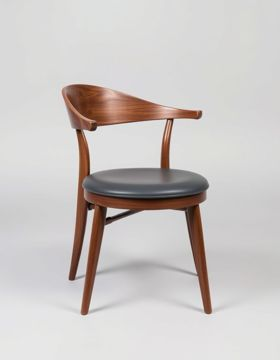
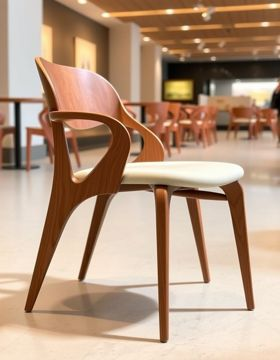
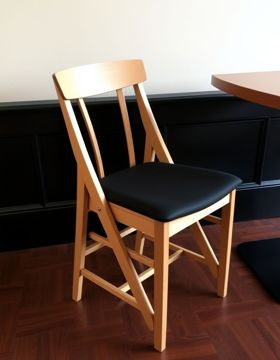
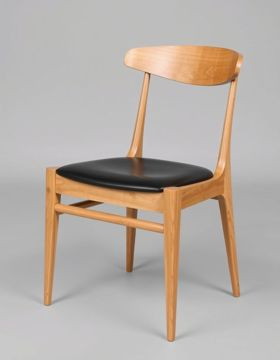

In [5]:
def data_uri(path, width=360):
    im = Image.open(path); im.thumbnail((width, width))
    buf = io.BytesIO(); im.convert("RGB").save(buf, format="JPEG", quality=80)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

rows = []
for e in log:
    if e["kind"] == "plan":
        rows.append(f"<tr><td>{e['step']}</td><td>plan</td><td><b>Checklist</b><br>{'<br>'.join(e['checklist'])}"
                    f"<br><b>Idea</b><br>{e['idea']}</td></tr>")
    elif e["kind"] == "image":
        rows.append(f"<tr><td>{e['step']}</td><td>image</td><td><img src='{data_uri(e['image'])}' width='180'><br>{e['prompt']}</td></tr>")
    else:
        checks = "<br>".join(("✓ " if c["passed"] else "✗ ") + f"{c['criterion']}: {c['why']}" for c in e["checks"])
        rows.append(f"<tr><td>{e['step']}</td><td>check</td><td>{checks}<br><b>Decision:</b> {e['decision']}. {e['change']}</td></tr>")
display(HTML("<table style='text-align:left'>" + "".join(rows) + "</table>"))

## 6. Count

This counts the steps, the failed checks and the decisions the agent made on its own, and saves the images side by side as rounds.jpg. Pick one of the agent's decisions you disagree with, and write down what you would have done instead.

9 steps, 4 images, 8 of 20 checks failed
5 decisions made by the agent (the checklist, and each keep-or-revise), none reviewed by a person


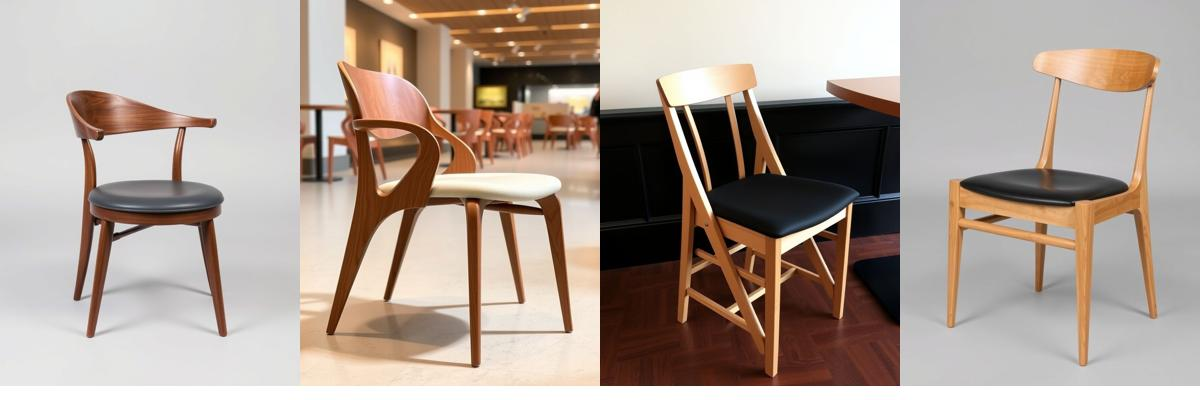

In [6]:
images = [e for e in log if e["kind"] == "image"]
checks = [c for e in log if e["kind"] == "check" for c in e["checks"]]
decisions = [e for e in log if e["kind"] in ("plan", "check")]
print(f"{len(log)} steps, {len(images)} images, {sum(not c['passed'] for c in checks)} of {len(checks)} checks failed")
print(f"{len(decisions)} decisions made by the agent (the checklist, and each keep-or-revise), none reviewed by a person")
strip = Image.new("RGB", (len(images) * 300, 400), "white")
for i, e in enumerate(images):
    im = Image.open(e["image"]); im.thumbnail((300, 400)); strip.paste(im, (i * 300, 0))
strip.save("rounds.jpg", quality=90)
strip